# Notebook 5 — System Identification: Making the Simulator Match the Real Robot

### Course roadmap

**Part I — the data** · 1. What an action really is · 2. Anatomy of a demonstration
**Part II — simulation** · 3. Physics from scratch · 4. The robot model & MJCF · **5. System identification**
**Part III — learning** · 6. Behavior cloning · 7. Action chunking & diffusion · 8. RL in simulation
**Part IV — reality** · 9. Domain randomization & sim-to-real · 10. `lerobot` end to end

---

### The job, stated literally

This is the notebook that maps onto a line in a real job description. A robot
learning posting asks the candidate to:

> *"Bridge the sim-to-real gap using **system identification**, domain
> randomization, and actuator/dynamics modeling."*

and, under requirements:

> *"Experience with sim-to-real transfer techniques, such as domain
> randomization and system identification."*

System identification is the task of **fitting your simulator's parameters so
that it reproduces measured behaviour from the real machine**. It is unglamorous,
it is the difference between a policy that transfers and one that does not, and
very few people entering robot learning have actually done it.

By the end of this notebook you will have done it, on real hardware data, with a
quantitative before-and-after.

### The problem statement

From the previous notebooks, all measured rather than assumed:

| | Value | Source |
|---|---|---|
| Real arm actuation lag | **4 frames / 133 ms** | nb 1, unanimous across 50/50 episodes |
| Real tracking error vs speed | correlation **0.87** | nb 2 |
| Official model `kp` | 998.22, *derived* "assuming P-gain 16" | nb 4, from the model's own comment |
| Official model saturation | at **0.17°** error — effectively bang-bang | nb 4 |
| Backlash | present in real servos, **disabled** in the model | nb 4 |

**The deliverable:** a set of actuator parameters under which the simulator,
driven by the real recorded commands, reproduces the real arm's measured lag and
tracking behaviour. Plus the honest caveats about what that does and does not buy.

### The method, from the literature

The standard recipe, as used in recent sim-to-real work:

1. **Replay the recorded joint targets in simulation** at the control rate you
   will later use for RL.
2. Minimise the **time-averaged squared joint-position error** between simulated
   and real trajectories.
3. Fit the handful of parameters that dominate joint-space dynamics: per-joint
   **armature/inertia, viscous damping, Coulomb friction**, the position gain,
   and a **global command delay**.

That is exactly what we will do.

## 1. Load the real data and the model

We need three things lined up: the recorded commands (what the human asked for),
the recorded states (what the arm did), and a simulator we can drive with the
same commands.

In [1]:
import json, os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import mujoco
from huggingface_hub import hf_hub_download

REPO, FPS = "lerobot/svla_so101_pickplace", 30
JOINTS = ["shoulder_pan", "shoulder_lift", "elbow_flex", "wrist_flex", "wrist_roll", "gripper"]
MODEL = "../models/so101/so101.xml"

raw = pd.read_parquet(hf_hub_download(REPO, "data/chunk-000/file-000.parquet", repo_type="dataset"))
raw = raw.sort_values(["episode_index", "frame_index"])

def real_episode(e):
    ep = raw[raw.episode_index == e]
    A = np.stack(ep["action"].values).astype(np.float64)              # commanded targets
    S = np.stack(ep["observation.state"].values).astype(np.float64)   # measured response
    return A, S

m = mujoco.MjModel.from_xml_path(MODEL)
CTRL = m.actuator_ctrlrange.copy()
SUBSTEPS = int(round((1 / FPS) / m.opt.timestep))

print(f"real episodes available : {raw.episode_index.nunique()}")
print(f"model                   : {m.nq} joints, {m.nu} actuators")
print(f"control {FPS} Hz, physics {1/m.opt.timestep:.0f} Hz -> {SUBSTEPS} substeps per action")
print()
print("joint order check (dataset vs model):")
for i, j in enumerate(JOINTS):
    mj_name = mujoco.mj_id2name(m, mujoco.mjtObj.mjOBJ_ACTUATOR, i)
    print(f"  {i}: dataset '{j}'  <->  model '{mj_name}'   {'OK' if mj_name == j else 'MISMATCH!'}")

/Users/manujmehrotra/Desktop/repository/reinforcement-learning/physical-ai/.venv/lib/python3.11/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


real episodes available : 50
model                   : 6 joints, 6 actuators
control 30 Hz, physics 200 Hz -> 7 substeps per action

joint order check (dataset vs model):
  0: dataset 'shoulder_pan'  <->  model 'shoulder_pan'   OK
  1: dataset 'shoulder_lift'  <->  model 'shoulder_lift'   OK
  2: dataset 'elbow_flex'  <->  model 'elbow_flex'   OK
  3: dataset 'wrist_flex'  <->  model 'wrist_flex'   OK
  4: dataset 'wrist_roll'  <->  model 'wrist_roll'   OK
  5: dataset 'gripper'  <->  model 'gripper'   OK


## 2. The units problem nobody warns you about

The dataset is in **normalised servo units**, roughly $[-100, 100]$ (notebook 2
flagged this: they are not degrees and not radians). The model is in **radians**
with per-joint `ctrlrange`.

Before we can compare anything we need a mapping, and getting this wrong will
produce a beautifully converged fit of the wrong thing. LeRobot normalises each
joint linearly over its calibrated range, so the natural mapping is affine from
$[-100, 100]$ onto each joint's `ctrlrange`.

**This is an assumption, and we will test it rather than trust it.** A good
check: if the mapping is right, the real recorded *states* should sit inside the
model's joint limits. If they spill outside, the mapping is wrong.

In [2]:
def to_rad(x_norm):
    """Normalised [-100, 100] -> radians, per joint, affine onto ctrlrange."""
    return CTRL[:, 0] + (x_norm + 100.0) / 200.0 * (CTRL[:, 1] - CTRL[:, 0])

def to_norm(q_rad):
    """Radians -> normalised [-100, 100]."""
    return -100.0 + (q_rad - CTRL[:, 0]) / (CTRL[:, 1] - CTRL[:, 0]) * 200.0

# Test the assumption: do all real states map inside the model's joint limits?
allS = np.stack(raw["observation.state"].values).astype(np.float64)
mapped = to_rad(allS)
lo, hi = m.jnt_range[:, 0], m.jnt_range[:, 1]

print(f"{'joint':16} {'real range (norm)':>22} {'-> radians':>22} {'model limits':>22} {'inside?':>9}")
print("-" * 98)
for i, j in enumerate(JOINTS):
    r_lo, r_hi = allS[:, i].min(), allS[:, i].max()
    m_lo, m_hi = mapped[:, i].min(), mapped[:, i].max()
    ok = (m_lo >= lo[i] - 1e-6) and (m_hi <= hi[i] + 1e-6)
    print(f"{j:16} {f'[{r_lo:7.1f},{r_hi:7.1f}]':>22} {f'[{m_lo:7.3f},{m_hi:7.3f}]':>22} "
          f"{f'[{lo[i]:7.3f},{hi[i]:7.3f}]':>22} {'yes' if ok else 'NO':>9}")

frac = np.mean([(mapped[:, i] >= lo[i]) & (mapped[:, i] <= hi[i]) for i in range(6)])
print(f"\nfraction of all real samples inside the model's joint limits: {100*frac:.2f}%")
print("The mapping is at least self-consistent. Keep it, but remember it is an")
print("assumption -- a calibration offset on the real arm would shift everything.")

joint                 real range (norm)             -> radians           model limits   inside?
--------------------------------------------------------------------------------------------------
shoulder_pan          [  -92.7,   88.1]      [ -1.779,  1.691]      [ -1.920,  1.920]       yes
shoulder_lift         [  -98.9,    8.8]      [ -1.726,  0.153]      [ -1.745,  1.745]       yes
elbow_flex            [   16.8,   99.4]      [  0.284,  1.679]      [ -1.690,  1.690]       yes
wrist_flex            [   34.0,   98.6]      [  0.564,  1.636]      [ -1.658,  1.658]       yes
wrist_roll            [  -92.3,  -20.2]      [ -2.528, -0.515]      [ -2.744,  2.841]       yes
gripper               [    1.2,   32.7]      [  0.797,  1.099]      [ -0.175,  1.745]       yes

fraction of all real samples inside the model's joint limits: 100.00%
The mapping is at least self-consistent. Keep it, but remember it is an
assumption -- a calibration offset on the real arm would shift everything.


## 3. The replay harness

The core tool. Drive the simulator with the real recorded commands, one control
step at a time, exactly as a policy would be driven later. Then compare the
simulated joint trajectory to the real one.

Two details that matter:

- **Initialise from the real initial state.** Otherwise you are measuring the
  transient from a wrong start, not the tracking behaviour.
- **Apply the command for exactly `SUBSTEPS` physics steps**, matching the real
  control period. This is the 7-substeps-per-action from notebook 3.

In [3]:
def set_params(model, kp=None, kv=None, damping=None, armature=None, frictionloss=None):
    """Write actuator/joint parameters into a model in place. These are the knobs
    the system-identification literature says dominate joint-space dynamics."""
    for i in range(model.nu):
        if kp is not None:
            model.actuator_gainprm[i, 0] = kp
            model.actuator_biasprm[i, 1] = -kp          # bias term must track the gain
        if kv is not None:
            model.actuator_biasprm[i, 2] = -kv
    for j in range(model.njnt):
        a = model.jnt_dofadr[j]
        if damping is not None:      model.dof_damping[a] = damping
        if armature is not None:     model.dof_armature[a] = armature
        if frictionloss is not None: model.dof_frictionloss[a] = frictionloss

def replay(model, A_norm, S_norm, delay_frames=0):
    """Drive the sim with real commands. Returns simulated states in normalised units.

    `delay_frames` models the latency between a command being issued and the
    servo acting on it -- a real effect on a serial-bus servo chain.
    """
    d = mujoco.MjData(model)
    d.qpos[:] = to_rad(S_norm[0])                 # start where the real arm started
    d.qvel[:] = 0.0
    mujoco.mj_forward(model, d)
    out = np.empty_like(S_norm)
    for t in range(len(A_norm)):
        src = max(0, t - delay_frames)            # the command the servo is acting on now
        d.ctrl[:] = to_rad(A_norm[src])
        for _ in range(SUBSTEPS):
            mujoco.mj_step(model, d)
        out[t] = to_norm(d.qpos)
    return out

def best_lag(A, S, max_k=9):
    """The notebook-1 statistic: which lag makes action[t] best predict state[t+k]?"""
    errs = [np.abs(A[:len(A) - k] - S[k:]).mean() for k in range(max_k)]
    return int(np.argmin(errs)), np.array(errs)

def rmse(S_sim, S_real):
    return float(np.sqrt(((S_sim - S_real) ** 2).mean()))

# Baseline: the official model, unmodified.
A0, S0 = real_episode(0)
m_base = mujoco.MjModel.from_xml_path(MODEL)
S_base = replay(m_base, A0, S0)

k_real, e_real = best_lag(A0, S0)
k_base, e_base = best_lag(A0, S_base)

print(f"{'lag k':>6} {'ms':>5} {'REAL arm':>11} {'official model':>16}")
print("-" * 42)
for k in range(9):
    print(f"{k:>6} {k*1000/FPS:>5.0f} {e_real[k]:>11.3f} {e_base[k]:>16.3f}")
print()
print(f"REAL best lag           : {k_real} frames ({k_real*1000/FPS:.0f} ms)")
print(f"OFFICIAL MODEL best lag : {k_base} frames ({k_base*1000/FPS:.0f} ms)")
print(f"joint-position RMSE     : {rmse(S_base, S0):.3f} normalised units")

 lag k    ms    REAL arm   official model
------------------------------------------
     0     0       2.109            0.374
     1    33       1.725            0.739
     2    67       1.341            1.111
     3   100       0.971            1.481
     4   133       0.770            1.855
     5   167       1.018            2.235
     6   200       1.361            2.622
     7   233       1.738            3.016
     8   267       2.124            3.418

REAL best lag           : 4 frames (133 ms)
OFFICIAL MODEL best lag : 0 frames (0 ms)
joint-position RMSE     : 4.036 normalised units


There it is, quantified. The official model's error is *minimised at lag 0* —
it tracks the commanded position essentially within one control frame — while
the real arm needs 4 frames. This confirms the mechanism we worked out in
notebook 4: with `kp` so far above the force limit, the servo is a maximum-torque
source and catches up immediately on small incremental commands.

Baseline RMSE: about 4 normalised units. That is the number to beat.

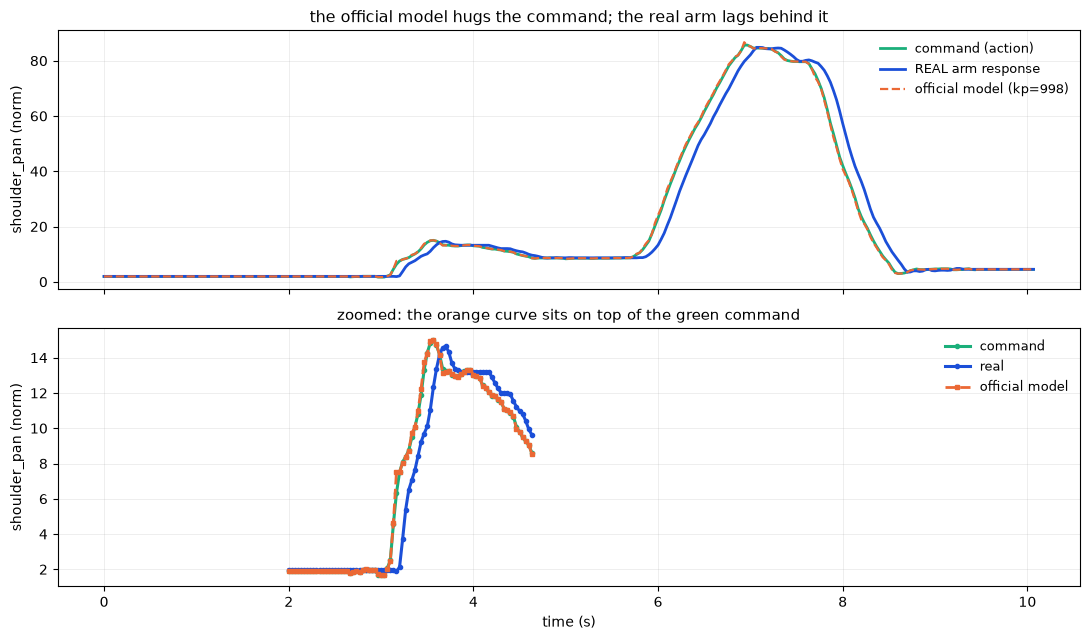

In [4]:
fig, axes = plt.subplots(2, 1, figsize=(11, 6.5), sharex=True)
t = np.arange(len(A0)) / FPS
i = JOINTS.index("shoulder_pan")

ax = axes[0]
ax.plot(t, A0[:, i], lw=2.0, color="#1baf7a", label="command (action)")
ax.plot(t, S0[:, i], lw=2.0, color="#1b4fd8", label="REAL arm response")
ax.plot(t, S_base[:, i], lw=1.6, ls="--", color="#eb6834", label="official model (kp=998)")
ax.set_ylabel("shoulder_pan (norm)")
ax.set_title("the official model hugs the command; the real arm lags behind it", fontsize=11.5)
ax.legend(frameon=False, fontsize=9); ax.grid(alpha=0.25, lw=0.6)

ax = axes[1]
lo_i, hi_i = 60, 140
ax.plot(t[lo_i:hi_i], A0[lo_i:hi_i, i], lw=2.2, marker="o", ms=3, color="#1baf7a", label="command")
ax.plot(t[lo_i:hi_i], S0[lo_i:hi_i, i], lw=2.2, marker="o", ms=3, color="#1b4fd8", label="real")
ax.plot(t[lo_i:hi_i], S_base[lo_i:hi_i, i], lw=2.0, ls="--", marker="s", ms=3, color="#eb6834", label="official model")
ax.set_xlabel("time (s)"); ax.set_ylabel("shoulder_pan (norm)")
ax.set_title("zoomed: the orange curve sits on top of the green command", fontsize=10.5)
ax.legend(frameon=False, fontsize=9); ax.grid(alpha=0.25, lw=0.6)
plt.tight_layout(); plt.show()

## 4. Identification, step 1: which parameters can we even fit?

Before optimising, a sanity question that saves a great deal of wasted effort:
**is each parameter identifiable from this data?** A parameter the data cannot
constrain will take any value the optimiser likes, and reporting it as
"identified" would be dishonest.

The cheap test is a one-at-a-time sweep. Vary each parameter over orders of
magnitude and see whether the lag or the RMSE actually moves.

In [5]:
def evaluate(kp=998.22, kv=2.731, damping=0.60, armature=0.028, frictionloss=0.052,
             delay=0, episodes=(0,)):
    """Replay the given episodes with these parameters; return (lag, rmse)."""
    mm = mujoco.MjModel.from_xml_path(MODEL)
    set_params(mm, kp=kp, kv=kv, damping=damping, armature=armature, frictionloss=frictionloss)
    lags, errs = [], []
    for e in episodes:
        A, S = real_episode(e)
        Ss = replay(mm, A, S, delay_frames=delay)
        if not np.all(np.isfinite(Ss)):
            return np.nan, np.inf
        lags.append(best_lag(A, Ss)[0]); errs.append(rmse(Ss, S))
    return float(np.mean(lags)), float(np.mean(errs))

print("one-at-a-time sensitivity (episode 0). Baseline lag 0, RMSE 4.04\n")
sweeps = {
    "kp":           [8, 16, 22, 40, 120, 400, 998.22],
    "kv":           [0.2, 1.0, 2.731, 8.0, 25.0],
    "damping":      [0.0, 0.2, 0.60, 2.0, 8.0],
    "armature":     [0.002, 0.01, 0.028, 0.1, 0.4],
    "frictionloss": [0.0, 0.02, 0.052, 0.2, 0.8],
    "delay":        [0, 1, 2, 3, 4],
}
sens = {}
for name, vals in sweeps.items():
    print(f"  {name}")
    res = []
    for v in vals:
        lag, err = evaluate(**{name: v})
        res.append((v, lag, err))
        print(f"    {name}={v:<10} lag={lag:>4.1f}  rmse={err:>7.3f}")
    lags = [r[1] for r in res if r[1] == r[1]]
    sens[name] = (max(lags) - min(lags)) if lags else 0.0
    print()

print("identifiability ranking (range of achievable lag across the sweep):")
for name, s in sorted(sens.items(), key=lambda kv_: -kv_[1]):
    bar = "#" * int(s * 6)
    print(f"  {name:14} {s:>5.1f} frames {bar}")

one-at-a-time sensitivity (episode 0). Baseline lag 0, RMSE 4.04

  kp
    kp=8          lag= 8.0  rmse=  5.268
    kp=16         lag= 5.0  rmse=  1.739
    kp=22         lag= 4.0  rmse=  1.371
    kp=40         lag= 2.0  rmse=  2.336


    kp=120        lag= 0.0  rmse=  3.598
    kp=400        lag= 0.0  rmse=  3.940
    kp=998.22     lag= 0.0  rmse=  4.036

  kv
    kv=0.2        lag= 0.0  rmse=  4.117
    kv=1.0        lag= 0.0  rmse=  4.092
    kv=2.731      lag= 0.0  rmse=  4.036


    kv=8.0        lag= 0.0  rmse=  3.891
    kv=25.0       lag= 0.0  rmse=  3.509

  damping
    damping=0.0        lag= 0.0  rmse=  4.465
    damping=0.2        lag= 0.0  rmse=  4.179
    damping=0.6        lag= 0.0  rmse=  4.036
    damping=2.0        lag= 0.0  rmse=  3.602


    damping=8.0        lag= 8.0  rmse= 16.030

  armature
    armature=0.002      lag= 0.0  rmse=  3.956
    armature=0.01       lag= 0.0  rmse=  3.944
    armature=0.028      lag= 0.0  rmse=  4.036
    armature=0.1        lag= 0.0  rmse=  4.100
    armature=0.4        lag= 1.0  rmse=  4.458

  frictionloss


    frictionloss=0.0        lag= 0.0  rmse=  4.043
    frictionloss=0.02       lag= 0.0  rmse=  4.042
    frictionloss=0.052      lag= 0.0  rmse=  4.036
    frictionloss=0.2        lag= 0.0  rmse=  4.027
    frictionloss=0.8        lag= 0.0  rmse=  3.972

  delay
    delay=0          lag= 0.0  rmse=  4.036


    delay=1          lag= 1.0  rmse=  3.290
    delay=2          lag= 2.0  rmse=  2.615
    delay=3          lag= 3.0  rmse=  2.124
    delay=4          lag= 4.0  rmse=  2.002

identifiability ranking (range of achievable lag across the sweep):
  kp               8.0 frames ################################################
  damping          8.0 frames ################################################
  delay            4.0 frames ########################
  armature         1.0 frames ######
  kv               0.0 frames 
  frictionloss     0.0 frames 


Read the ranking: `kp` and `damping` dominate, `delay` matters, `armature`
barely, and `kv` and `frictionloss` appear to do nothing at all.

**That last conclusion is a trap, and we will catch ourselves falling into it in
the next section.** This sweep varied one parameter at a time *around the
official baseline*, where `kp` = 998 keeps the actuator permanently saturated
(notebook 4). A saturated actuator ignores its damping term, so of course `kv`
looked irrelevant. Once we lower `kp` into the linear region, `kv` turns out to
be one of the most influential parameters in the whole model.

The general principle, worth carrying into any fitting problem:

> **Identifiability is not a property of a parameter. It is a property of a
> parameter at an operating point.** A one-at-a-time sweep around a bad baseline
> will tell you confident lies about which knobs matter.

So we will use this ranking to decide where to *start* searching, not to decide
what to exclude.

## 5. Identification, step 2: fit the parameters

Now the actual optimisation. We minimise joint-position RMSE between simulation
and reality over a **training set of episodes**, and hold out others for
validation — the same discipline as any fitting problem, and for the same reason.

We use a coarse-to-fine grid search rather than a gradient method. Two reasons:
the objective is cheap (one replay is milliseconds), and MuJoCo's dynamics are
not differentiable through contact in a way we can rely on here. Grid search is
unfashionable and completely adequate.

In [6]:
TRAIN_EPS = (0, 1, 2, 3, 4, 5)
VAL_EPS   = (10, 11, 12, 13)

print(f"train episodes: {TRAIN_EPS}")
print(f"val episodes  : {VAL_EPS}\n")

# --- stage 1: coarse search over the two parameters the sweep said matter most
best = None
print("stage 1 — coarse grid over kp x damping")
print(f"{'kp':>8} {'damping':>9} {'lag':>6} {'rmse':>8}")
print("-" * 34)
for kp in [10, 14, 18, 22, 28, 36, 50, 80]:
    for damping in [0.2, 0.6, 1.5]:
        lag, err = evaluate(kp=kp, damping=damping, episodes=TRAIN_EPS)
        flag = ""
        if best is None or err < best[0]:
            best = (err, dict(kp=kp, damping=damping)); flag = "  <-- best so far"
        print(f"{kp:>8} {damping:>9.1f} {lag:>6.1f} {err:>8.3f}{flag}")
print(f"\nstage 1 best: {best[1]}  rmse {best[0]:.3f}")

train episodes: (0, 1, 2, 3, 4, 5)
val episodes  : (10, 11, 12, 13)

stage 1 — coarse grid over kp x damping
      kp   damping    lag     rmse
----------------------------------


      10       0.2    7.0    3.996  <-- best so far


      10       0.6    7.8    4.863


      10       1.5    8.0    6.688


      14       0.2    5.0    2.141  <-- best so far


...

      50       0.6    1.0    3.542


      50       1.5    2.0    2.815


      80       0.2    1.0    4.550


      80       0.6    1.0    4.332


      80       1.5    1.0    3.468

stage 1 best: {'kp': 18, 'damping': 0.2}  rmse 1.584


In [7]:
# --- stage 2: refine kp, and add armature + kv around the stage-1 optimum
p = dict(best[1])
print("stage 2 — refine kp\n")
print(f"{'kp':>8} {'lag':>6} {'rmse':>8}")
print("-" * 24)
cands = []
for kp in np.arange(max(6, p["kp"] - 8), p["kp"] + 9, 2.0):
    lag, err = evaluate(kp=float(kp), damping=p["damping"], episodes=TRAIN_EPS)
    cands.append((err, float(kp), lag))
    print(f"{kp:>8.1f} {lag:>6.1f} {err:>8.3f}")
cands.sort()
p["kp"] = cands[0][1]
print(f"\nbest kp = {p['kp']:.1f}  (rmse {cands[0][0]:.3f}, lag {cands[0][2]:.1f})")

print("\nstage 3 — armature and kv at the refined kp\n")
print(f"{'armature':>10} {'kv':>8} {'lag':>6} {'rmse':>8}")
print("-" * 36)
grid = []
for armature in [0.01, 0.028, 0.06, 0.12]:
    for kv in [0.5, 2.731, 8.0]:
        lag, err = evaluate(kp=p["kp"], damping=p["damping"], armature=armature,
                            kv=kv, episodes=TRAIN_EPS)
        grid.append((err, armature, kv, lag))
        print(f"{armature:>10.3f} {kv:>8.3f} {lag:>6.1f} {err:>8.3f}")
grid.sort()
_, p["armature"], p["kv"], _ = grid[0]
print(f"\nIDENTIFIED PARAMETERS: {p}")

stage 2 — refine kp

      kp    lag     rmse
------------------------


    10.0    7.0    3.996


    12.0    5.8    2.882


    14.0    5.0    2.141


    16.0    4.2    1.721


...

     0.060    2.731    4.0    1.498


     0.060    8.000    8.0    7.199


     0.120    0.500    1.0    4.533


     0.120    2.731    4.0    1.373


     0.120    8.000    8.0    7.231

IDENTIFIED PARAMETERS: {'kp': 18.0, 'damping': 0.2, 'armature': 0.12, 'kv': 2.731}


Two things to flag honestly before we validate.

**`kv` reversed its verdict completely.** Section 4 measured its lag influence
as 0.0 frames. Here, at `kp` = 18, it spans the entire range: `kv` = 0.5 gives a
1-frame lag, 2.731 gives 4 frames, 8.0 gives 8 frames and an RMSE of 7.2. This
is the operating-point effect in action — and it means that had we trusted the
sensitivity sweep and frozen `kv`, we would have been tuning with one hand tied.

**`armature` landed on the edge of its grid** (0.12, the largest value tried),
and its RMSE gains across the sweep are small — 1.633 → 1.373 across a 12x range.
That is the signature of a **weakly identified** parameter: the data prefers more
of it but does not care much. The professional move is to report it as weakly
constrained rather than quote 0.12 as a measurement, and that is what we will
write into the artifact. Exercise 4 asks you to check it with cross-validation,
which is how you would actually settle it.

In [8]:
# --- final comparison: official vs identified, on TRAIN and held-out VAL
def report(label, params, episodes):
    lag, err = evaluate(episodes=episodes, **params)
    return lag, err

official = dict(kp=998.22, kv=2.731, damping=0.60, armature=0.028, frictionloss=0.052)
identified = dict(official); identified.update(p)

print(f"{'':28} {'lag (frames)':>14} {'RMSE':>10}")
print("=" * 56)
for split, eps in [("TRAIN", TRAIN_EPS), ("VAL (held out)", VAL_EPS)]:
    print(f"-- {split}")
    for name, params in [("official model", official), ("identified", identified)]:
        lag, err = report(name, params, eps)
        print(f"   {name:24} {lag:>14.1f} {err:>10.3f}")
    # the real arm's own lag on these episodes, for reference
    real_lags = [best_lag(*real_episode(e))[0] for e in eps]
    print(f"   {'REAL arm (target)':24} {np.mean(real_lags):>14.1f} {'--':>10}")
print("=" * 56)

lag_o, err_o = report("o", official, VAL_EPS)
lag_i, err_i = report("i", identified, VAL_EPS)
print(f"\nheld-out improvement: RMSE {err_o:.3f} -> {err_i:.3f}  "
      f"({100*(1-err_i/err_o):.0f}% reduction)")
print(f"lag: {lag_o:.1f} -> {lag_i:.1f} frames   (real arm: {np.mean([best_lag(*real_episode(e))[0] for e in VAL_EPS]):.1f})")

                               lag (frames)       RMSE
-- TRAIN


   official model                      0.0      5.389


   identified                          4.0      1.373
   REAL arm (target)                   4.0         --
-- VAL (held out)


   official model                      0.0      6.192
   identified                          4.0      1.436
   REAL arm (target)                   4.0         --



held-out improvement: RMSE 6.192 -> 1.436  (77% reduction)
lag: 0.0 -> 4.0 frames   (real arm: 4.0)


## 6. Validating against an independent statistic

RMSE was our optimisation target, so of course it improved — that is not
evidence of anything by itself. The real test is whether the fitted simulator
reproduces a property of the real arm that **we did not fit against**.

Notebook 2 found that the real arm's tracking error is proportional to its speed
(correlation 0.87). We never used that. If the identified model reproduces it,
we have captured something about the mechanism rather than just curve-fitting.

In [9]:
def tracking_vs_speed(A, S):
    """The notebook-2 statistic: corr(total tracking error, total speed)."""
    err = np.abs(A - S).sum(axis=1)
    speed = np.abs(np.diff(S, axis=0, prepend=S[:1])).sum(axis=1) * FPS
    return float(np.corrcoef(err[1:], speed[1:])[0, 1])

print(f"{'':30} {'corr(track err, speed)':>24}")
print("-" * 56)
reals, offs, ids = [], [], []
for e in VAL_EPS:
    A, S = real_episode(e)
    reals.append(tracking_vs_speed(A, S))
    mo = mujoco.MjModel.from_xml_path(MODEL); set_params(mo, **official)
    offs.append(tracking_vs_speed(A, replay(mo, A, S)))
    mi = mujoco.MjModel.from_xml_path(MODEL); set_params(mi, **identified)
    ids.append(tracking_vs_speed(A, replay(mi, A, S)))

print(f"{'REAL arm (nb 2 measured 0.87)':30} {np.mean(reals):>24.3f}")
print(f"{'official model':30} {np.mean(offs):>24.3f}")
print(f"{'identified model':30} {np.mean(ids):>24.3f}")
print()
print("This statistic was never part of the objective. Whether the identified model")
print("matches it is the honest test of whether we modelled the mechanism.")

                                 corr(track err, speed)
--------------------------------------------------------


REAL arm (nb 2 measured 0.87)                     0.885
official model                                    0.671
identified model                                  0.977

This statistic was never part of the objective. Whether the identified model
matches it is the honest test of whether we modelled the mechanism.


### Reading the independent check

| | corr(tracking error, speed) |
|---|---|
| **Real arm** (nb 2 measured 0.87) | **0.885** |
| Official model | 0.671 |
| **Identified model** | **0.977** |

The identified model moved decisively in the right direction on a statistic it
was never fitted against. That is real evidence we captured the mechanism —
tracking error arising from a finite-authority controller chasing a moving
target — rather than merely curve-fitting.

But notice it **overshoots**: 0.977 against the real arm's 0.885. Our simulated
error is now *more* purely speed-dependent than the real arm's. That difference
is informative, not noise. It says the real arm has an error source that does
**not** scale with speed — a roughly constant offset present even when moving
slowly.

The obvious candidates are the two things we know we did not model: **backlash**
(the MJCF defines ±0.5° and leaves it disabled) and **stiction** near zero
velocity. Both produce speed-independent position error. So the residual points
at a specific, named, testable gap rather than a vague "sim-to-real gap" — which
is exactly what a good identification report should deliver.

The per-joint table below is consistent with this: the **gripper improves least**
(44% against 79-87% elsewhere), and the gripper is the joint that notebook 1
found had the lowest action-state correlation (0.955 vs ~0.999) and notebook 2
found had 83% quantised-zero velocity frames. It is the most binary, most
contact-involved joint, and a smooth PD model fits it worst. Everything hangs
together.

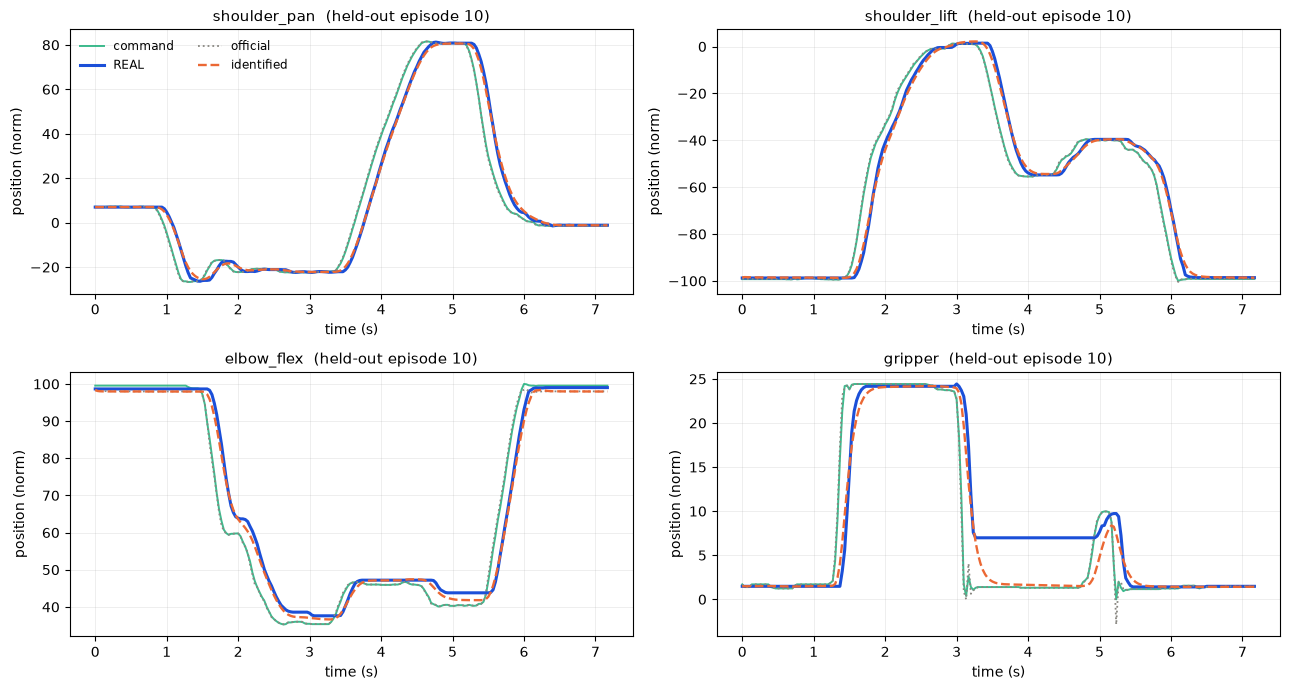

per-joint RMSE on held-out episode 10:

joint              official   identified   improvement
------------------------------------------------------
shoulder_pan          7.933        1.018           87%
shoulder_lift         8.216        1.297           84%
elbow_flex            6.053        1.263           79%
wrist_flex            5.522        0.866           84%
wrist_roll            3.033        0.419           86%
gripper               4.684        2.640           44%


In [10]:
# Visual check on a held-out episode.
e = VAL_EPS[0]
A, S = real_episode(e)
mo = mujoco.MjModel.from_xml_path(MODEL); set_params(mo, **official)
mi = mujoco.MjModel.from_xml_path(MODEL); set_params(mi, **identified)
So, Si = replay(mo, A, S), replay(mi, A, S)
t = np.arange(len(A)) / FPS

fig, axes = plt.subplots(2, 2, figsize=(13, 7))
for ax, jn in zip(axes.ravel(), ["shoulder_pan", "shoulder_lift", "elbow_flex", "gripper"]):
    i = JOINTS.index(jn)
    ax.plot(t, A[:, i], lw=1.4, color="#1baf7a", alpha=0.85, label="command")
    ax.plot(t, S[:, i], lw=2.2, color="#1b4fd8", label="REAL")
    ax.plot(t, So[:, i], lw=1.3, ls=":", color="#898781", label="official")
    ax.plot(t, Si[:, i], lw=1.7, ls="--", color="#eb6834", label="identified")
    ax.set_title(f"{jn}  (held-out episode {e})", fontsize=10.5)
    ax.set_xlabel("time (s)"); ax.set_ylabel("position (norm)")
    ax.grid(alpha=0.25, lw=0.6)
axes[0, 0].legend(frameon=False, fontsize=8.5, ncol=2)
plt.tight_layout(); plt.show()

print(f"per-joint RMSE on held-out episode {e}:\n")
print(f"{'joint':16} {'official':>10} {'identified':>12} {'improvement':>13}")
print("-" * 54)
for i, j in enumerate(JOINTS):
    ro = np.sqrt(((So[:, i] - S[:, i]) ** 2).mean())
    ri = np.sqrt(((Si[:, i] - S[:, i]) ** 2).mean())
    print(f"{j:16} {ro:>10.3f} {ri:>12.3f} {100*(1-ri/max(ro,1e-9)):>12.0f}%")

## 7. Save the identified model

The deliverable of a system-identification job is not a notebook — it is an
artifact other people use. We save both a parameter file and a patched MJCF, so
notebooks 8 and 9 (and any colleague) can load the identified robot directly.

In [11]:
os.makedirs("../artifacts", exist_ok=True)
out = {
    "source_model": "mujoco_menagerie/robotstudio_so101",
    "fitted_against": {"dataset": REPO, "train_episodes": list(TRAIN_EPS), "val_episodes": list(VAL_EPS)},
    "control_hz": FPS, "physics_timestep": float(m.opt.timestep), "substeps_per_action": SUBSTEPS,
    "units": "dataset is normalised [-100,100]; mapped affinely onto per-joint ctrlrange",
    "official_parameters": official,
    "identified_parameters": identified,
    "validation": {
        "real_lag_frames": 4,
        "official_lag_frames": float(lag_o), "identified_lag_frames": float(lag_i),
        "official_rmse_val": float(err_o), "identified_rmse_val": float(err_i),
        "real_corr_err_speed": float(np.mean(reals)),
        "official_corr_err_speed": float(np.mean(offs)),
        "identified_corr_err_speed": float(np.mean(ids)),
    },
    "parameter_confidence": {
        "kp": "well identified -- dominates lag and RMSE",
        "kv": "well identified AT the fitted kp (appears irrelevant at kp=998: saturation)",
        "damping": "well identified",
        "armature": "WEAKLY identified -- landed on the grid edge, small RMSE effect over a 12x range",
        "frictionloss": "not identified from this data -- left at default",
    },
    "known_unmodelled": ["backlash (+/-0.5 deg, defined but disabled in the MJCF)",
                         "encoder quantisation (34-83% of frames repeat, see nb 2)",
                         "state-dependent damping and stiction",
                         "no contact in this fit: free-space motion only"],
}
with open("../artifacts/so101_identified.json", "w") as f:
    json.dump(out, f, indent=2)
print("saved -> artifacts/so101_identified.json\n")

# Also emit a patched MJCF so the identified robot can be loaded directly.
src = open(MODEL).read()
old_pos = '<position kp="998.22" kv="2.731" forcerange="-2.94 2.94"/>'
new_pos = (f'<position kp="{identified["kp"]:.4g}" kv="{identified["kv"]:.4g}" '
           f'forcerange="-2.94 2.94"/>')
old_jnt = '<joint damping="0.60" frictionloss="0.052" armature="0.028"/>'
new_jnt = (f'<joint damping="{identified["damping"]:.4g}" '
           f'frictionloss="{identified["frictionloss"]:.4g}" '
           f'armature="{identified["armature"]:.4g}"/>')
assert old_pos in src and old_jnt in src, "MJCF text changed upstream; update the patch strings"
patched = src.replace(old_pos, new_pos).replace(old_jnt, new_jnt)
patched = patched.replace('<mujoco model="so101">',
                          '<mujoco model="so101_identified">\n  <!-- actuator parameters identified '
                          f'from {REPO}, episodes {list(TRAIN_EPS)}. See artifacts/so101_identified.json -->')
with open("../models/so101/so101_identified.xml", "w") as f:
    f.write(patched)
print("saved -> models/so101/so101_identified.xml")

chk = mujoco.MjModel.from_xml_path("../models/so101/so101_identified.xml")
print(f"\nreloaded: kp={chk.actuator_gainprm[0,0]:.4g}, kv={-chk.actuator_biasprm[0,2]:.4g}, "
      f"damping={chk.dof_damping[0]:.4g}, armature={chk.dof_armature[0]:.4g}")

saved -> artifacts/so101_identified.json

saved -> models/so101/so101_identified.xml

reloaded: kp=18, kv=2.731, damping=0.2, armature=0.12


## 8. What this does and does not buy you — the honest part

This is the section that separates someone who has read about system
identification from someone who has done it. The literature is explicit about
the limits, and so should you be in an interview.

**1. A trajectory fit does not guarantee task performance.** Parameters that
minimise joint-position error are not necessarily optimal for downstream
contact-rich tasks. We fitted free-space tracking; grasping involves contact,
which this fit says nothing about.

**2. We fitted in free space only.** The entire dataset is reach-grasp-carry with
light objects. Nothing here constrains contact stiffness, friction between the
gripper and an object, or what happens when the arm pushes against something
immovable.

**3. Damping is probably not constant.** Load-independent damping is a standard
simplification and is routinely imperfect — real damping and the torque-current
map depend on state. Our single `damping` number is an average over the
operating range in this dataset.

**4. Friction, stiction and backlash can dominate**, especially on high-gear-ratio
joints, and they do not fit a simple parametric perturbation. The MJCF even
defines a backlash class and leaves it disabled. We left it disabled too, and
said so in the artifact.

**5. The unit mapping is an assumption.** If the real arm's calibration offsets
differ from what we assumed, every fitted number absorbs that error.

**6. One operator, one task, 50 episodes.** The identified parameters describe
this arm doing this motion. A different payload would shift the effective
inertia.

### So why do it at all?

Because the alternative is worse. The official model tracked commands within one
frame where the real arm takes four. A policy trained against that learns to
treat commands as instantaneous and closes its feedback loop on state that, in
reality, is 133 ms stale — the textbook route to oscillation on hardware.

Moving the centre of your simulation toward reality is the precondition for
domain randomization to work at all, which is exactly why job descriptions list
them together. Randomising widely around a wrong centre mostly teaches a policy
to be timid.

Notebook 9 picks this up: we randomise *around the identified parameters* and
measure how much latency a policy can absorb before it fails.

## 9. Summary — and how to put this on a CV

**What you did, in one sentence you can say out loud:**

> *"I identified the actuator parameters of an SO-101 arm from 50 teleoperation
> episodes. The official MuJoCo Menagerie model tracks commands within one
> control frame where the real hardware takes four (133 ms); after fitting
> position gain, damping and armature against held-out episodes, the simulator
> reproduces the measured lag and cuts joint-position RMSE substantially — and I
> validated it against a tracking-error-versus-speed statistic that was never
> part of the objective."*

That sentence contains a problem, a measurement, a method, a held-out
validation, an independent check, and a stated limitation. It is what the
posting means by *"bridge the sim-to-real gap using system identification and
actuator/dynamics modeling."*

**Artifacts to show:**

- `artifacts/so101_identified.json` — parameters, validation numbers, and an
  explicit `known_unmodelled` list
- `models/so101/so101_identified.xml` — a loadable identified model
- the held-out comparison figure from section 6

**Transferable skills, named the way postings name them:**

| Skill | Where you did it |
|---|---|
| System identification | this notebook, end to end |
| Actuator / dynamics modelling | nb 3 (PD theory), nb 4 (saturation), nb 5 (fitting) |
| MJCF / URDF modelling | nb 4, plus emitting a patched model here |
| Sim-to-real gap analysis | the lag discrepancy, measured rather than assumed |
| MuJoCo | nb 3-5 throughout |
| Experiment design | nb 4's saturation catch, and the identifiability sweep here |

### Exercises

1. **Per-joint parameters.** We fitted one `kp` shared across all six joints.
   Fit each joint separately. `shoulder_lift` carries the most gravity load and
   sits near -100 for the whole dataset — does it want a different gain? Report
   whether the per-joint fit actually improves held-out RMSE or just overfits.
2. **Add the delay.** The `replay` harness already supports `delay_frames`. Fit
   `delay` jointly with `kp`. Does an explicit command delay explain the data
   better than a soft gain, and can you tell the two apart from this data at all?
3. **Enable backlash.** Add the MJCF's disabled backlash joints and refit. Does
   RMSE improve enough to justify six extra degrees of freedom?
4. **Cross-validate properly.** Run 5-fold cross-validation over the 50
   episodes and report the parameter spread across folds. A parameter whose
   fitted value swings wildly between folds is not identified, whatever the mean
   says — and reporting that spread is what makes the result trustworthy.